In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB5

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.utils.class_weight import compute_class_weight

from sklearn.preprocessing import label_binarize

In [ ]:
TRAIN_GROUNDTRUTH_PATH = "data/train/ISIC_2019_Training_GroundTruth.csv"
TEST_GROUNDTRUTH_PATH = "ham10000/HAM10000_Test_GroundTruth_Updated.csv"
TEST2_GROUNDTRUTH_PATH = "data/test/ISIC_2019_Test_GroundTruth.csv"


TRAIN_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input"  
TEST_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_images_part_12"  
TEST2_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_Input"  
IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20 

LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [22]:
def read_ds(gnd_path):
    """Read a dataset from CSV file and assign labels correspondingly."""
    gnd = pd.read_csv(gnd_path)
    gnd['y'] = gnd[LABELS].idxmax(axis=1)

    return gnd

def get_image_paths_and_labels(groundtruth, image_dir):
    """Generate image paths and corresponding labels from a groundtruth DataFrame."""
    image_paths = [
        os.path.join(image_dir, row['image'] + '.jpg') 
        for _, row in groundtruth.iterrows()
    ]
    labels = [
        LABELS.index(row['y']) 
        for _, row in groundtruth.iterrows()
    ]
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH) 
test_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH) 
test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)
train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
test_paths_2, test_labels_2 = get_image_paths_and_labels(test_groundtruth_2, TEST2_IMAGE_DIR)

In [43]:
# Image preprocessing function
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE[0], IMG_SIZE[1]])
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

/var/folders/vz/rgbmjfqn0nq0nvl3m3c5by_00000gn/T/ipykernel_4153/2426958069.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=LABELS, y=class_counts, palette='viridis')


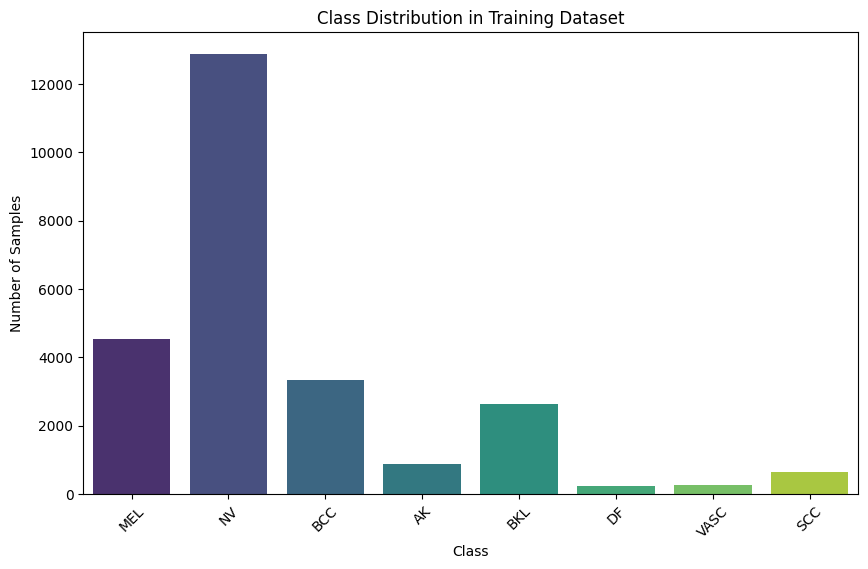

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = [train_labels.count(i) for i in range(len(LABELS))]

plt.figure(figsize=(10, 6))
sns.barplot(x=LABELS, y=class_counts, palette='viridis')
plt.title('Class Distribution in Training Dataset')
plt.xlabel('Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.show()


# Data Augmentation

In [44]:
# Apply augmentation
def preprocess_and_augment(file_path, label):
    image = tf.io.read_file(file_path)
    image = tf.image.decode_jpeg(image, 
                                 channels=3)
    image = tf.image.resize(image, [IMG_SIZE[0], IMG_SIZE[1]])
    image = tf.keras.applications.efficientnet.preprocess_input(image)
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
    image = tf.image.random_hue(image, max_delta=0.1)
    return image, label

In [45]:
shuffle_size = 512
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset\
    .map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(512)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset_2 = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test_dataset_2 = test_dataset_2\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

# Model

In [88]:
base_model = EfficientNetB5(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.005))(x)
x = layers.Dropout(0.5)(x)
x = layers.BatchNormalization()(x)

outputs = layers.Dense(len(LABELS), activation="softmax")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"] 
)

In [89]:
model_path = "model_checkpoint.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="accuracy",
    mode="max",
    save_best_only=True,
)

# if os.path.exists(model_path):
#     model = tf.keras.models.load_model(model_path)

early_stop = tf.keras.callbacks.EarlyStopping(
    restore_best_weights=True,
    monitor="val_loss",
    patience=5,  
)

In [90]:
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb5 (Functional)     │ (None, 15, 15, 2048)   │    28,513,527 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │         4,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,568,767 (112.80 MB)

 Trainable params: 1,054,216 (4.02 MB)

 Non-trainable params: 28,514,551 (108.77 MB)

In [50]:
# Imbalance in the dataset
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

# Training & Saving the Model

In [ ]:
# Train the model
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight={i: weight for i, weight in enumerate(class_weights)},
    callbacks=[checkpoint, early_stop]
)

Epoch 1/20
 27/792 ━━━━━━━━━━━━━━━━━━━━ 4:24 346ms/step - accuracy: 0.1151 - loss: 0.9774

KeyboardInterrupt: 

In [ ]:
# Save the final model in h5 format
model.save("final_model.h5")

In [74]:
# model = models.load_model('efficientnet-b5.keras')

In [54]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb5 (Functional)     │ (None, 15, 15, 2048)   │    28,513,527 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │         4,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,748,553 (216.48 MB)

 Trainable params: 27,181,832 (103.69 MB)

 Non-trainable params: 2,384,887 (9.10 MB)

 Optimizer params: 27,181,834 (103.69 MB)

### HAM10000

In [55]:
# HAM10000
test_loss, test_accuracy = model.evaluate(test_dataset)
print(f"HAM10000 Test Accuracy: {test_accuracy}")
print(f"HAM10000 Test Loss: {test_loss}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 414s 1s/step - accuracy: 0.7910 - loss: 1.5202
HAM10000 Test Accuracy: 0.8168746829032898
HAM10000 Test Loss: 1.4922981262207031


In [56]:
y_true = np.concatenate([y for _, y in test_dataset], axis=0)
y_pred = model.predict(test_dataset)
y_pred = np.argmax(y_pred, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 425s 1s/step


In [57]:
score_report = classification_report(y_true, y_pred, target_names=[LABELS[i] for i in range(8)], zero_division=0)
print(score_report)

              precision    recall  f1-score   support

         MEL       0.58      0.60      0.59      1113
          NV       0.95      0.88      0.91      6705
         BCC       0.64      0.89      0.74       514
          AK       0.43      0.43      0.43       327
         BKL       0.72      0.71      0.71      1099
          DF       0.85      0.99      0.92       115
        VASC       0.66      1.00      0.79       142
         SCC       0.00      0.00      0.00         0

    accuracy                           0.82     10015
   macro avg       0.60      0.69      0.64     10015
weighted avg       0.84      0.82      0.83     10015



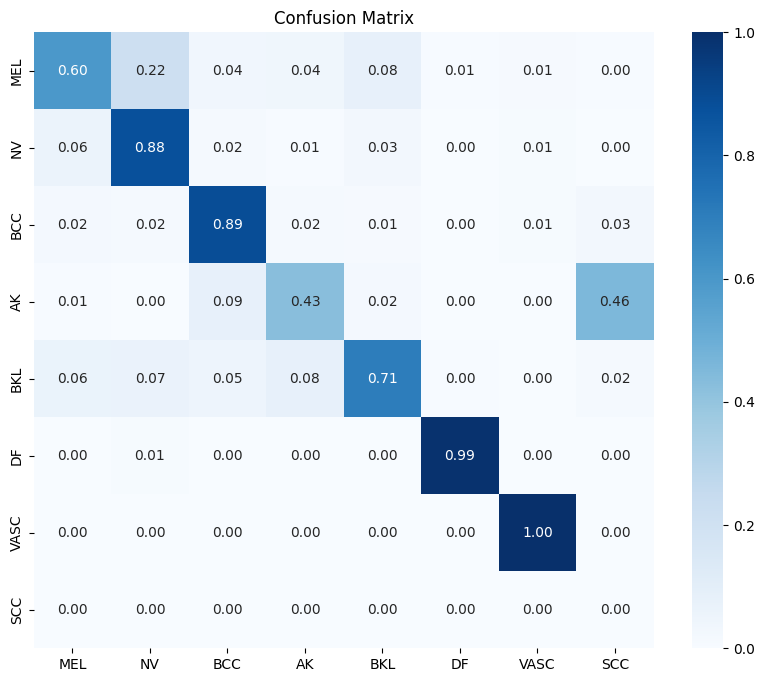

In [58]:
conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

### ISIC 2019

In [59]:
# ISIC 2019
test_loss, test_accuracy = model.evaluate(test_dataset_2)
print(f"HAM10000 Test Accuracy: {test_accuracy}")
print(f"HAM10000 Test Loss: {test_loss}")

258/258 ━━━━━━━━━━━━━━━━━━━━ 536s 2s/step - accuracy: 0.6248 - loss: 2.2348
HAM10000 Test Accuracy: 0.5088613629341125
HAM10000 Test Loss: 2.6885218620300293


In [60]:
y2_true = np.concatenate([y for _, y in test_dataset_2], axis=0)
y2_pred = model.predict(test_dataset_2)
y2_pred = np.argmax(y2_pred, axis=1)

2025-03-06 15:25:11.831999: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


258/258 ━━━━━━━━━━━━━━━━━━━━ 333s 1s/step


In [61]:
score_report = classification_report(y2_true, 
                                     y2_pred, 
                                     target_names=[LABELS[i] for i in range(8)])
print(score_report)

              precision    recall  f1-score   support

         MEL       0.69      0.28      0.40      3374
          NV       0.83      0.72      0.77      2495
         BCC       0.40      0.76      0.52       975
          AK       0.23      0.62      0.34       374
         BKL       0.33      0.45      0.38       660
          DF       0.24      0.47      0.32        91
        VASC       0.19      0.66      0.30       104
         SCC       0.18      0.47      0.26       165

    accuracy                           0.51      8238
   macro avg       0.39      0.55      0.41      8238
weighted avg       0.63      0.51      0.52      8238



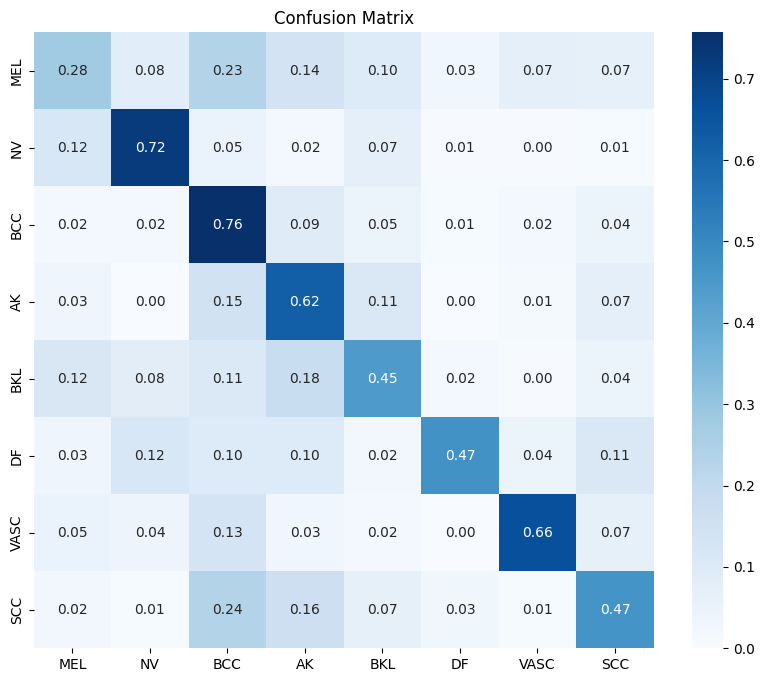

In [62]:
conf_matrix = confusion_matrix(y2_true, 
                               y2_pred, 
                               normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
[[3.1294605e-01 6.6491902e-01 4.3859653e-04 2.0808104e-05 1.7679380e-02
  6.0513270e-05 3.9141593e-03 2.1426613e-05]]
[[0.4833434  0.13515154 0.09832251 0.00298814 0.15316693 0.00180107
  0.01400873 0.11121775]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
[[2.8988594e-01 6.8936640e-01 2.8883864e-04 1.6678059e-04 1.7399833e-02
  3.4259388e-06 2.8692260e-03 1.9489766e-05]]
[[3.9008629e-02 9.1820461e-01 2.0575444e-03 1.1613718e-03 3.7915882e-02
  4.5003158e-05 9.8432228e-04 6.2272552e-04]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
[[0.16635105 0.00992407 0.5054273  0.0023533  0.01146538 0.00309162
  0.23457535 0.06681197]]
[[2.3805751e-03 6.6437479e-03 2.5121819e-02 1.7288299e-03 1.1311095e-02
  7.4803219e-03 4.3501655e-04 9.4489866e-01]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
[[2.90734490e-04 1.07472406e-04 

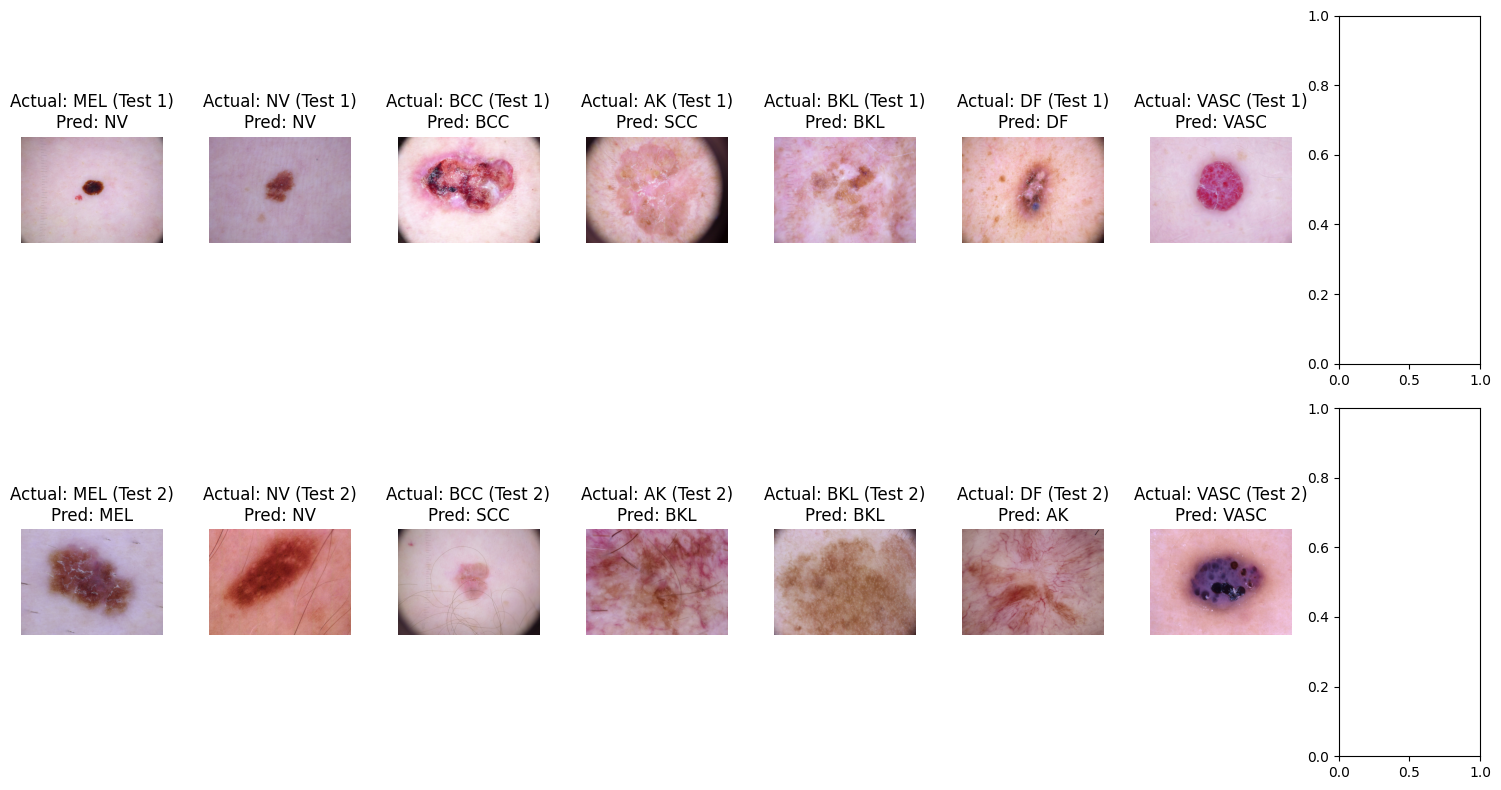

In [ ]:
import random
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image

LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

def preprocess_image(file_path):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE[0], IMG_SIZE[1]])
    img = tf.keras.applications.efficientnet.preprocess_input(img)

    return img

def pick_images_based_on_index(test_paths, test_labels):
    label_images = {label: {"test1": None, "test2": None} for label in range(len(LABELS))}
    
    for idx, label in zip(range(len(test_labels)), test_labels):
        if test_paths[idx] is None:
            print(f"Warning: No image path for index {idx} in test_paths.")
            continue
        if label_images[label]["test1"] is None:
            label_images[label]["test1"] = test_paths[idx]
        elif label_images[label]["test2"] is None:
            label_images[label]["test2"] = test_paths[idx]

    return label_images

label_images_test1 = pick_images_based_on_index(test_paths, test_labels)
label_images_test2 = pick_images_based_on_index(test_paths_2, test_labels_2)

fig, axes = plt.subplots(2, len(LABELS), figsize=(15, 8))

for i, label in enumerate(range(len(LABELS))):
    img_path_1 = label_images_test1[label]["test1"]
    img_path_2 = label_images_test2[label]["test2"]

    if img_path_1 is None or img_path_2 is None:
        print(f"Skipping label {label} because of None image path(s).")
        continue

    actual_label_1 = LABELS[test_labels[test_paths.index(img_path_1)]]
    actual_label_2 = LABELS[test_labels_2[test_paths_2.index(img_path_2)]]
    img_1 = preprocess_image(img_path_1)
    img_2 = preprocess_image(img_path_2)
    img_1 = tf.expand_dims(img_1, axis=0)
    img_2 = tf.expand_dims(img_2, axis=0)

    pred_1 = model.predict(img_1)
    pred_2 = model.predict(img_2)
    print(pred_1)
    print(pred_2)
    
    label_1 = LABELS[np.argmax(pred_1)]
    label_2 = LABELS[np.argmax(pred_2)]
    
    img_1_display = image.load_img(img_path_1)
    img_2_display = image.load_img(img_path_2)
    
    axes[0, i].imshow(img_1_display)
    axes[0, i].set_title(f"Actual: {actual_label_1} (Test 1)\nPred: {label_1}")
    axes[0, i].axis("off")
    
    axes[1, i].imshow(img_2_display)
    axes[1, i].set_title(f"Actual: {actual_label_2} (Test 2)\nPred: {label_2}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
memory_info = tf.config.experimental.get_memory_info('GPU:0')

print("Memory Usage (Bytes):", memory_info)